# Figure 3: differential expression for emphysema progression

Panels based on data:
- **3a** cell type-specific DEGs (fast vs slow progression) in the lung single-cell data
- **3b** cell type-specific DEGs in the blood single-cell data
- **3c** validation of the lung DEGs in the GeoMx spatial data
- **3e** validation of the DEGs in the predicted cell type-specific expression of COPDGene bulk blood RNA-seq (classical monocytes)
- **3f** overlap of the DEGs between lung, blood and the bulk validation

Panel 3d is a schematic and is not generated here.

In [1]:
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from adjustText import adjust_text
from matplotlib.transforms import Affine2D
from matplotlib_venn import venn3
from statsmodels.stats.multitest import multipletests

from figure_style import DENSE_FONT_SIZE, FONT_SIZE, SMALL_FONT_SIZE, figure_size, save_panel, set_style

set_style()
DATA = Path("../data")

In [2]:
cell_type_colors = {
    'AT1': '#ffff00', 'AT2_B': '#1ce6ff', 'AT2_S': '#ff34ff', 'Aerocytes': '#ff4a46', 'Artery': '#008941', 'Basal': '#006fa6',
    'Ciliated': '#a30059', 'Club cells': '#ffdbe5', 'DC1': '#7a4900', 'DC2': '#0000a6', 'Fibroblasts_adventitial': '#63ffac',
    'Fibroblasts_adventitial_lipo': '#b79762', 'Fibroblasts_alveolar': '#004d43', 'HSP_endo': '#8fb0ff', 'IGHD_pos_B': '#997d87',
    'IGHD_neg_B': '#5a0007', 'IL6_endo': '#809693', 'Lymphatic': '#6a3a4c', 'Macrophages_Smoking_induced': '#1b4400',
    'Macrophages_Alveolar': '#4fc601', 'Macrophages_Alveolar_APOE': '#3b5dff', 'Macrophages_Interstitial': '#4a3b53',
    'Macrophages_div': '#ff2f80', 'Mast': '#61615a', 'Mesothelium': '#ba0900', 'MDSC': '#9467bd', 'Monocytes_Classical': '#6b7900',
    'Monocytes_Non_Classical': '#00c2a0', 'NK': '#ffaa92', 'Pericytes': '#ff90c9', 'Plasma': '#b903aa', 'Rare': '#d16100',
    'SMC': '#ddefff', 'TASC': '#000035', 'T_senescence_associated': '#7b4f4b', 'T_CD4': '#a1c299', 'T_CD8': '#300018',
    'T_div': '#0aa6d8', 'T_reg': '#013349', 'Veins_pulmonary': "#162b27", 'Veins_systemic': '#372101', 'gCaps': '#ffb500',
    'mDC': '#c2ffed', 'pDC': '#a079bf',
    # Blood
    "Platelet": "darkgrey", "B": "#997d87", "ILC": "orange", "Monocytes_PRMT7+": "#1b4400",
}

# Style of the gene labels on the volcano plots
bbox_props = dict(boxstyle="round,pad=0.15", facecolor="white", linewidth=0.5, alpha=0.8)

## DEGs in the lung and blood single-cell data

Results of the pseudobulk differential expression analysis (fast vs slow progression, separately for emphysema patients and controls) per cell type.

In [3]:
lung_markers = pd.read_csv(DATA / "6_lung_deg_results.csv", index_col=0)
blood_markers = pd.read_csv(DATA / "7_blood_deg_results.csv", index_col=0)

lung_hits = lung_markers[lung_markers["significant"]]
blood_hits = blood_markers[blood_markers["significant"]]
print("Lung hits:", len(lung_hits), "Blood hits:", len(blood_hits))

Lung hits: 583 Blood hits: 255


In [4]:
lung_genes = lung_hits["gene"].unique()
blood_genes = blood_hits["gene"].unique()
overlapping_genes = blood_genes[np.isin(blood_genes, lung_genes)]
print(len(lung_genes), "lung genes,", len(blood_genes), "blood genes,", len(overlapping_genes), "overlapping genes")
overlapping_genes

506 lung genes, 244 blood genes, 10 overlapping genes


array(['ABR', 'FAS', 'CD151', 'IL6ST', 'ADAM19', 'AREG', 'HSBP1L1',
       'CST3', 'PRAG1', 'ZBTB16'], dtype=object)

In [5]:
merged_markers = pd.merge(
    lung_hits[lung_hits["gene"].isin(overlapping_genes)],
    blood_hits[blood_hits["gene"].isin(overlapping_genes)],
    on="gene",
    suffixes=["_lung", "_blood"],
)
same_sign_markers = merged_markers[np.sign(merged_markers["logFC_lung"]) == np.sign(merged_markers["logFC_blood"])].copy()
same_sign_markers[["gene", "logFC_lung", "logFC_blood", "cell_type_lung", "cell_type_blood"]]

,gene,logFC_lung,logFC_blood,cell_type_lung,cell_type_blood
1,ZBTB16,1.506759,0.910082,T_CD4,T_CD4
2,CST3,-0.595994,-0.667310,Monocytes_Classical,T_CD4
3,AREG,1.134809,1.994743,Macrophages_Alveolar,T_CD4
4,ZBTB16,1.805488,0.910082,Macrophages_Alveolar,T_CD4
5,IL6ST,0.649108,0.501035,T_CD4,T_CD4
6,HSBP1L1,0.591783,0.500650,Macrophages_Alveolar,T_CD4
7,FAS,-1.462495,-0.564624,Macrophages_Alveolar,T_CD4


In [6]:
def plot_volcano(markers, tissue, alpha, logfc_threshold, titles, logfc_clip=3, legend_anchor=(1.05, 1), height_mm=42):
    """Volcano plots of fast vs slow progression DEGs for controls (left) and emphysema patients (right)."""
    markers = markers.copy()
    markers["logFC"] = np.clip(markers["logFC"], -logfc_clip, logfc_clip)

    fig, axes = plt.subplots(figsize=figure_size(105, height_mm), ncols=2, sharey=True)
    for i in range(2):
        sns.scatterplot(
            data=markers[markers["Emphysema"] == i], x="logFC", y="-log10(FDR)", hue="cell_type",
            s=3, ax=axes[i], legend=bool(i), lw=0, palette=cell_type_colors,
        )
        axes[i].set_title(titles[i])
        ylim = axes[i].get_ylim()
        axes[i].vlines(logfc_threshold, *ylim, color="black", linestyle="--", lw=0.75)
        axes[i].vlines(-logfc_threshold, *ylim, color="black", linestyle="--", lw=0.75)
        axes[i].set_ylim(ylim)
        axes[i].set_xlim(-logfc_clip, logfc_clip)
        axes[i].hlines(-np.log10(alpha), *axes[i].get_xlim(), color="black", linestyle="--", lw=0.75)
        if i:
            axes[1].legend(bbox_to_anchor=legend_anchor, loc="upper left", frameon=False, title="Cell type", markerscale=2, fontsize=DENSE_FONT_SIZE, labelspacing=0.15, handletextpad=0.2, borderaxespad=0)

    # Label genes that are DEGs with the same direction in lung and blood
    labels_df = same_sign_markers.sort_values(f"FDR_{tissue}").drop_duplicates(subset=["gene", f"Emphysema_{tissue}"])
    for emphysema in [0, 1]:
        sub = labels_df[labels_df[f"Emphysema_{tissue}"] == emphysema]
        if sub.empty:
            continue
        texts = [
            axes[emphysema].text(
                x=row[f"logFC_{tissue}"], y=row[f"-log10(FDR)_{tissue}"], s=row["gene"], fontsize=SMALL_FONT_SIZE,
                ha="left" if row[f"logFC_{tissue}"] > 0 else "right", va="bottom", bbox=bbox_props, zorder=10,
            )
            for _, row in sub.iterrows()
        ]
        adjust_text(
            texts, ax=axes[emphysema], arrowprops=dict(arrowstyle="-", color="gray", lw=0.4),
            expand_points=(1.6, 1.8), expand_text=(1.2, 1.4), force_points=(0.5, 0.7),
        )

### Fig. 3a: lung

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


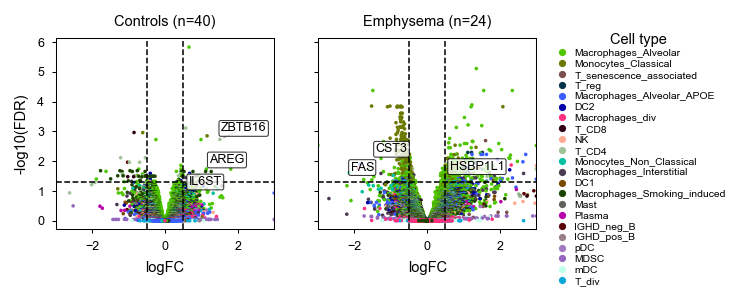

In [7]:
plot_volcano(lung_markers, tissue="lung", alpha=0.05, logfc_threshold=0.5, titles=["Controls (n=40)", "Emphysema (n=24)"], legend_anchor=(1.05, 1.05))
save_panel("Fig_3_a_lung_DEGs")
plt.show()

### Fig. 3b: blood

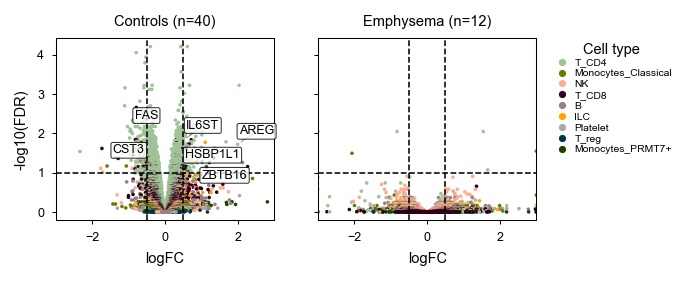

In [8]:
plot_volcano(blood_markers, tissue="blood", alpha=0.1, logfc_threshold=0.5, titles=["Controls (n=40)", "Emphysema (n=12)"], height_mm=40)
save_panel("Fig_3_b_blood_DEGs")
plt.show()

## Fig. 3c: validation of the lung DEGs in the spatial data

Log fold changes (fast vs slow progression) of the lung single-cell DEGs in the GeoMx data per region and emphysema status (E: emphysema, N: no emphysema).
Only genes with a consistent direction across cell types in the single-cell data are kept; p-values are Benjamini-Hochberg corrected per region;
log fold changes which are not significant ($p_{adj}$ > 0.1) or whose direction disagrees with the single-cell data are set to 0.

In [9]:
spatial_df = pd.read_csv(DATA / "8_GeoMx_DEG_results.csv")
spatial_df.columns = spatial_df.columns.str.replace("paremchyma", "parenchyma")

significant_hits = lung_markers[lung_markers["significant"]]
print("Lung hits measured in the spatial data:", spatial_df["Gene"].isin(significant_hits["gene"].unique()).sum())

spatial_hits = spatial_df[spatial_df["Gene"].isin(significant_hits["gene"].unique())].set_index("Gene")

Lung hits measured in the spatial data: 300


In [10]:
# Exclude genes with diverse dynamics in different cell types
repeating_genes = significant_hits.groupby("gene").describe()["logFC"]
repeating_genes = repeating_genes[repeating_genes["count"] > 1]
diverse_dynamics_genes = repeating_genes[repeating_genes["min"] * repeating_genes["max"] < 0]
significant_hits = significant_hits[~significant_hits["gene"].isin(diverse_dynamics_genes.index)]
diverse_dynamics_genes.index.tolist()

['CHORDC1',
 'DNAJA1',
 'DNAJA4',
 'DNAJB1',
 'HSP90AA1',
 'HSP90AB1',
 'HSPA1A',
 'HSPA1B',
 'HSPE1',
 'HSPH1',
 'NPM1',
 'TCP1']

In [11]:
regions = [
    "FASTvsSLOW | E_airway", "FASTvsSLOW | E_lymphoid follicle", "FASTvsSLOW | E_parenchyma", "FASTvsSLOW | E_vessel",
    "FASTvsSLOW | NOE_airway", "FASTvsSLOW | NOE_lymphoid follicle", "FASTvsSLOW | NOE_parenchyma", "FASTvsSLOW | NOE_vessel",
]
readable_group_names = {
    "LFC_FASTvsSLOW | E_airway": "E_airway", "LFC_FASTvsSLOW | E_lymphoid follicle": "E_lymphoid follicle",
    "LFC_FASTvsSLOW | E_parenchyma": "E_parenchyma", "LFC_FASTvsSLOW | E_vessel": "E_ vessel",
    "LFC_FASTvsSLOW | NOE_airway": "N_airway", "LFC_FASTvsSLOW | NOE_lymphoid follicle": "N_lymphoid follicle",
    "LFC_FASTvsSLOW | NOE_parenchyma": "N_parenchyma", "LFC_FASTvsSLOW | NOE_vessel": "N_vessel",
}

for region in regions:
    spatial_hits[f"PVAL_adj_{region}"] = multipletests(spatial_hits[f"PVAL_{region}"], method="fdr_bh")[1]

(spatial_hits[[f"PVAL_adj_{region}" for region in regions]] < 0.05).sum()

PVAL_adj_FASTvsSLOW | E_airway                  5
PVAL_adj_FASTvsSLOW | E_lymphoid follicle       9
PVAL_adj_FASTvsSLOW | E_parenchyma              5
PVAL_adj_FASTvsSLOW | E_vessel                  0
PVAL_adj_FASTvsSLOW | NOE_airway                0
PVAL_adj_FASTvsSLOW | NOE_lymphoid follicle     2
PVAL_adj_FASTvsSLOW | NOE_parenchyma           31
PVAL_adj_FASTvsSLOW | NOE_vessel                1
dtype: int64

In [12]:
# Zero-out logFCs which are not statistically significant or have a different direction in spatial and single-cell data
for region in regions:
    spatial_hits.loc[spatial_hits[f"PVAL_adj_{region}"] > 0.1, f"LFC_{region}"] = 0

    for gene, logfc in spatial_hits.loc[spatial_hits[f"PVAL_adj_{region}"] < 0.1, f"LFC_{region}"].items():
        sc_progression_coef = significant_hits.loc[significant_hits["gene"] == gene, "logFC"].mean()
        if not (sc_progression_coef * logfc) > 0:
            print("gene:", gene, "region:", f"{region:40}", "LFC in SC:", round(sc_progression_coef, 2), "LFC in spatial:", round(logfc, 2), sep="\t")
            spatial_hits.loc[gene, f"LFC_{region}"] = 0
            spatial_hits.loc[gene, f"PVAL_adj_{region}"] = 1

gene:	DNAJA1	region:	FASTvsSLOW | E_lymphoid follicle        	LFC in SC:	nan	LFC in spatial:	-0.7
gene:	DNM2	region:	FASTvsSLOW | E_lymphoid follicle        	LFC in SC:	0.69	LFC in spatial:	-0.55
gene:	EGFL7	region:	FASTvsSLOW | E_lymphoid follicle        	LFC in SC:	1.97	LFC in spatial:	-0.71
gene:	GNAQ	region:	FASTvsSLOW | E_lymphoid follicle        	LFC in SC:	0.58	LFC in spatial:	-0.52
gene:	IER5	region:	FASTvsSLOW | E_lymphoid follicle        	LFC in SC:	1.03	LFC in spatial:	-0.61
gene:	B2M	region:	FASTvsSLOW | E_parenchyma               	LFC in SC:	-0.61	LFC in spatial:	0.78
gene:	HLA-C	region:	FASTvsSLOW | E_parenchyma               	LFC in SC:	-0.55	LFC in spatial:	0.53
gene:	RPL18A	region:	FASTvsSLOW | E_parenchyma               	LFC in SC:	-0.82	LFC in spatial:	0.54
gene:	RPL6	region:	FASTvsSLOW | E_parenchyma               	LFC in SC:	-0.56	LFC in spatial:	0.4
gene:	RPL7A	region:	FASTvsSLOW | E_parenchyma               	LFC in SC:	-0.69	LFC in spatial:	0.44
gene:	RPS28	regio

In [13]:
# Remove ribosomal genes as many of them had diverging dynamics between SC and spatial data
selected_genes = spatial_hits.index[spatial_hits[[f"LFC_{region}" for region in regions]].abs().sum(axis=1) > 0]
selected_genes = selected_genes[~selected_genes.str.startswith("RPS") & ~selected_genes.str.startswith("RPL")]
len(selected_genes)

58

In [14]:
def pval_to_asterisk(pval):
    if pval < 0.001:
        return "∗∗∗"
    elif pval < 0.01:
        return "∗∗"
    elif pval < 0.05:
        return "∗"
    elif pval < 0.1:
        return "·"
    return ""


pvals_annotation = spatial_hits.loc[selected_genes, [f"PVAL_adj_{region}" for region in regions]].map(pval_to_asterisk)
pvals_annotation.columns = [f"LFC_{region}" for region in regions]  # Rename columns to match logFC table for correct plotting

gene_order = spatial_hits.loc[selected_genes, [f"LFC_{region}" for region in regions]].mean(axis=1).sort_values().index
displayed_hits = spatial_hits.loc[gene_order, [f"LFC_{region}" for region in regions]]
displayed_hits = displayed_hits.loc[:, displayed_hits.sum() != 0]  # Drop regions with no DEGs
displayed_annotation = pvals_annotation.loc[gene_order, displayed_hits.columns]
displayed_hits = displayed_hits.rename(columns=readable_group_names)

# Keep genes with at least one hit with p < 0.05, and CST3
filtered_005 = ((displayed_annotation != "·") & (displayed_annotation != "")).any(axis=1)
filtered_005.loc["CST3"] = True
filtered_005.sum()

30

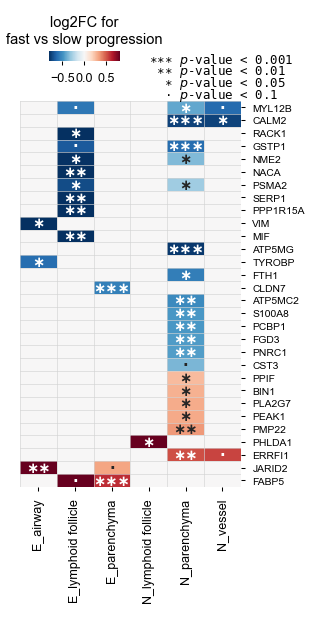

In [15]:
g = sns.clustermap(
    displayed_hits.loc[filtered_005], yticklabels=True, cmap="RdBu_r", center=0, vmin=-0.8, vmax=0.8, figsize=figure_size(60, 105),
    annot=displayed_annotation.loc[filtered_005], col_cluster=False, row_cluster=False, fmt="", dendrogram_ratio=(0.02, 0.18),
    annot_kws={"size": FONT_SIZE, "weight": "bold", "family": "DejaVu Sans"}, cbar_kws={"label": "log2FC for\nfast vs slow progression", "orientation": "horizontal"},
)
g.ax_heatmap.set_ylabel("")
g.ax_heatmap.tick_params(axis="y", labelsize=DENSE_FONT_SIZE)  # Gene names
g.ax_cbar.set_position([0.14, 0.9, 0.2, 0.015])
g.ax_cbar.tick_params(labelsize=SMALL_FONT_SIZE)
g.ax_cbar.xaxis.label.set_va("center")
g.ax_cbar.xaxis.label.set_ha("center")
g.ax_cbar.xaxis.label.set_rotation(0)
g.ax_cbar.xaxis.set_label_position("top")

p_value_labels = ["∗∗∗ $p$-value < 0.001", " ∗∗ $p$-value < 0.01", "  ∗ $p$-value < 0.05", "  · $p$-value < 0.1"]
for i, label in enumerate(p_value_labels):
    g.ax_heatmap.text(x=3.5, y=-3.2 + i * 0.9, s=label, ha="left", va="center", fontsize=SMALL_FONT_SIZE, fontdict={"family": "monospace"})

# Grid between the cells
g.ax_heatmap.set_xticks(np.arange(displayed_hits.shape[1] + 1), minor=True)
g.ax_heatmap.set_yticks(np.arange(filtered_005.sum() + 1), minor=True)
g.ax_heatmap.grid(which="minor", color="lightgrey", linewidth=0.3)
g.ax_heatmap.tick_params(which="minor", length=0)

save_panel("Fig_3_c_spatial_validation")
plt.show()

## Fig. 3e: validation of the DEGs in COPDGene bulk blood RNA-seq

Cell type-specific expression was predicted from bulk blood RNA-seq with BayesPrism / InstaPrism, and tested for association with emphysema progression (limma).
Single-cell DEGs are mapped to the cell types available in the deconvolution; a DEG is confirmed if its direction agrees with the lung or the blood single-cell result.

In [16]:
cell_type_mapping = {
    # From lung
    'T_senescence_associated': 'T_CD4', 'T_CD4': 'T_CD4', 'T_CD8': 'T_CD8', 'T_reg': 'T_reg', 'Monocytes_Classical': 'Monocytes_Classical',
    'Macrophages_Smoking_induced': 'Monocytes_PRMT7+', 'Monocytes_Non-Classical': 'Monocytes_Non-Classical',
    # From blood
    "CD4_Naive": "T_CD4", "CD8_TEM": "T_CD8", "Monocytes_PRMT7+": "Monocytes_PRMT7+", "Treg": "T_reg",
}

bulk_validation_markers = defaultdict(list)
for markers in [lung_hits, blood_hits]:
    for _, row in markers.dropna(subset=["gene"]).iterrows():
        bulk_cell_type = cell_type_mapping.get(row["cell_type"])
        if bulk_cell_type is not None:
            bulk_validation_markers[bulk_cell_type].append(row["gene"])

{cell_type: len(genes) for cell_type, genes in bulk_validation_markers.items()}

{'Monocytes_Classical': 237,
 'T_CD4': 225,
 'T_CD8': 34,
 'T_reg': 17,
 'Monocytes_PRMT7+': 24}

In [17]:
validation_results = []
matching_genes = defaultdict(set)  # Genes whose direction in bulk agrees with lung or blood single-cell data, per cell type
bulk_results = {}

for bulk_cell_type, cell_type_markers in bulk_validation_markers.items():
    results_file = DATA / "9_bulk_dge_results" / f"{bulk_cell_type}_Design2_emphysema_progression.csv"
    if not results_file.exists():
        print("No gene expression predicted for markers in", bulk_cell_type)
        continue

    bulk_cell_type_results = pd.read_csv(results_file, index_col=0)
    bulk_cell_type_results["-log10(p_value)"] = -np.log10(bulk_cell_type_results["P.Value"])
    bulk_results[bulk_cell_type] = bulk_cell_type_results

    signature_genes = bulk_cell_type_results[bulk_cell_type_results.index.isin(cell_type_markers)]
    if not len(signature_genes):
        print("No gene expression predicted for markers in", bulk_cell_type)
        continue
    p_values_adjusted = multipletests(signature_genes["P.Value"], method="fdr_bh")[1]

    for i, (gene, row) in enumerate(signature_genes.iterrows()):
        blood_result = blood_hits[(blood_hits["gene"] == gene) & (blood_hits["cell_type"] == bulk_cell_type)]
        lung_result = lung_hits[(lung_hits["gene"] == gene) & (lung_hits["cell_type"] == bulk_cell_type)]
        blood_match = "N/A" if blood_result.empty else "Yes" if (row["logFC"] > 0) == (blood_result["logFC"].values[0] > 0) else "No"
        lung_match = "N/A" if lung_result.empty else "Yes" if (row["logFC"] > 0) == (lung_result["logFC"].values[0] > 0) else "No"
        validation_results.append([bulk_cell_type, gene, p_values_adjusted[i], row["logFC"], blood_match, lung_match])
        if blood_match == "Yes" or lung_match == "Yes":
            matching_genes[bulk_cell_type].add(gene)

validation_results = pd.DataFrame(validation_results, columns=["cell_type", "gene", "p_adj", "logFC_bulk", "Match_blood", "Match_lung"])
validation_results.sort_values("p_adj").head(15)

No gene expression predicted for markers in T_CD8


,cell_type,gene,p_adj,logFC_bulk,Match_blood,Match_lung
0,Monocytes_Classical,DDX60L,0.067782,0.0378,N/A,Yes
11,Monocytes_Classical,CST3,0.149442,-0.0404,N/A,Yes
9,Monocytes_Classical,PFN1,0.149442,-0.0213,N/A,Yes
8,Monocytes_Classical,TNFAIP6,0.149442,0.0646,N/A,Yes
7,Monocytes_Classical,NACA,0.149442,-0.0228,N/A,Yes
6,Monocytes_Classical,CD302,0.149442,0.0287,N/A,No
10,Monocytes_Classical,SH3BGRL3,0.149442,-0.0270,N/A,Yes
4,Monocytes_Classical,MEF2C,0.149442,-0.0552,N/A,No
3,Monocytes_Classical,S100A9,0.149442,0.0317,N/A,No
2,Monocytes_Classical,S100A10,0.149442,-0.0449,N/A,Yes


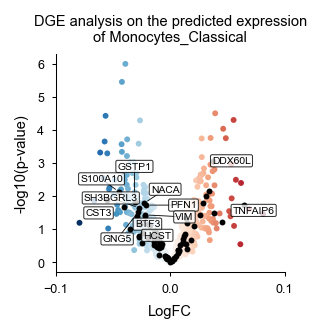

In [18]:
bulk_cell_type = "Monocytes_Classical"
bulk_cell_type_results = bulk_results[bulk_cell_type]
cell_type_markers = bulk_validation_markers[bulk_cell_type]
signature_genes = bulk_cell_type_results[bulk_cell_type_results.index.isin(cell_type_markers)]

plt.figure(figsize=figure_size(50, 48))
sns.scatterplot(bulk_cell_type_results[~bulk_cell_type_results.index.isin(cell_type_markers)], x="logFC", y="-log10(p_value)", hue="logFC", palette="RdBu_r", legend=False, s=8, lw=0)
sns.scatterplot(signature_genes, x="logFC", y="-log10(p_value)", color="black", legend=False, s=8, lw=0)

# Label confirmed lung DEGs with p < 0.05
texts = []
for gene in lung_hits.loc[lung_hits["cell_type"] == bulk_cell_type, "gene"]:
    if gene not in signature_genes.index or gene not in matching_genes[bulk_cell_type] or signature_genes.loc[gene, "P.Value"] > 0.05:
        continue
    x, y = bulk_cell_type_results.loc[gene, ["logFC", "-log10(p_value)"]]
    texts.append(plt.text(x, y, gene, fontsize=DENSE_FONT_SIZE, ha="left" if x > 0 else "right", va="center", bbox=bbox_props, zorder=10, color="black"))
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="black", lw=0.4), force_points=0.5, force_text=1)

sns.despine(top=True, right=True)
x_ticks = plt.xticks()[0]
plt.xticks(x_ticks[::2])
plt.xlabel("LogFC")
plt.ylabel("-log10(p-value)")
plt.title(f"DGE analysis on the predicted expression\nof {bulk_cell_type}")
save_panel("Fig_3_e_bulk_validation")
plt.show()

## Fig. 3f: overlap of the DEGs between lung, blood and the bulk validation

In [19]:
all_matching_genes = set().union(*matching_genes.values())
lung_hit_genes = set(lung_hits["gene"].dropna().unique())
blood_hit_genes = set(blood_hits["gene"].dropna().unique())
validation_hits = set(validation_results[validation_results["gene"].isin(all_matching_genes) & (validation_results["p_adj"] < 0.2)]["gene"])

intersection = lung_hit_genes & blood_hit_genes & validation_hits
intersection

{'CST3'}

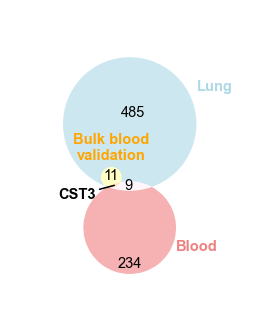

In [20]:
fig, ax = plt.subplots(figsize=figure_size(50, 65))
v = venn3(
    [lung_hit_genes, blood_hit_genes, validation_hits],
    set_labels=("Lung", "Blood", "Bulk blood \nvalidation  "),
    set_colors=("lightblue", "lightcoral", "orange"),
    alpha=0.6,
    ax=ax,
)

# Rotate the circles -90 degrees
rotation = Affine2D().rotate_deg(-90) + ax.transData
for patch in v.patches:
    if patch is not None:
        patch.set_transform(rotation)

# Rotate label positions: (x, y) -> (y, -x)
for label in list(v.set_labels) + list(v.subset_labels):
    if label is not None:
        x, y = label.get_position()
        label.set_position((y, -x))

# Centre of the three-way intersection: mean of a grid of points lying inside all three circles (in rotated coordinates)
circles = [(v.get_circle_center(i), v.get_circle_radius(i)) for i in range(3)]
grid = np.stack(np.meshgrid(np.linspace(-1, 1, 2001), np.linspace(-1, 1, 2001)), axis=-1).reshape(-1, 2)
inside_all = np.all([np.hypot(grid[:, 0] - center.x, grid[:, 1] - center.y) <= radius for center, radius in circles], axis=0)
intersection_center = grid[inside_all].mean(axis=0)
intersection_center = (intersection_center[1], -intersection_center[0])  # Rotate like the circles

v.get_label_by_id("111").set_text("")
validation_center, validation_radius = circles[2]
validation_center = (validation_center.y, -validation_center.x)
# Label the gene below-left of the validation circle, with a line ending at the centre of the three-way intersection
ax.annotate(
    ", ".join(sorted(intersection)), xy=intersection_center, xytext=(validation_center[0] - validation_radius - 0.04, intersection_center[1] - 0.07),
    ha="right", va="center", fontsize=FONT_SIZE, fontweight="bold",
    arrowprops=dict(arrowstyle="-", color="black", lw=0.75, shrinkA=0, shrinkB=0),
)

for label in v.set_labels:
    if label:
        label.set_fontsize(FONT_SIZE)
        label.set_fontweight("bold")
        text = label.get_text()
        label.set_color("lightcoral" if "Blood" in text and "Bulk" not in text else "lightblue" if "Lung" in text else "orange")
        if "Bulk" in text:  # Place the label just above the validation circle
            label.set_text("Bulk blood\nvalidation")
            label.set_horizontalalignment("center")
            label.set_verticalalignment("bottom")
            label.set_position((validation_center[0], validation_center[1] + validation_radius + 0.03))
        elif text == "Lung":
            label.set_horizontalalignment("left")

for label in v.subset_labels:
    if label:
        label.set_fontsize(FONT_SIZE)
        if label.get_text() == str(len(validation_hits) - len(intersection)):  # Centre of the validation circle, clear of the CST3 marker
            label.set_horizontalalignment("center")
            label.set_verticalalignment("center")
            label.set_position((validation_center[0], validation_center[1] + 0.01))
        elif label.get_text() == str(len(blood_hit_genes & lung_hit_genes) - len(intersection)):
            label.set_horizontalalignment("left")
        elif label.get_text() == str(len(blood_hit_genes - lung_hit_genes - validation_hits)):  # Blood hits only
            label.set_horizontalalignment("center")
        else:
            label.set_horizontalalignment("left")

ax.set_xlim(-0.8, 0.8)
ax.set_ylim(-1.0, 1.0)
ax.set_aspect("equal")
ax.axis("off")
save_panel("Fig_3_f_markers_overlap")
plt.show()